In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [2]:
datas = pd.read_csv('data/penguins.csv', sep=',')
datas.isnull().sum()

culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64

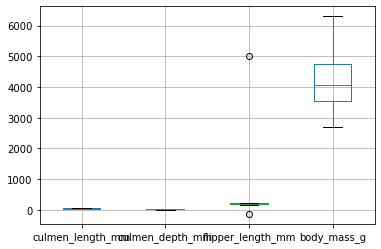

In [3]:
datas.boxplot()
plt.show()

In [5]:
df = datas.dropna()
df.isna().sum()

culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

In [6]:
df = df.loc[(df['flipper_length_mm']<4000) & (df['flipper_length_mm']>0)]
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE


In [7]:
df = pd.get_dummies(df)
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex_.,sex_FEMALE,sex_MALE
0,39.1,18.7,181.0,3750.0,0,0,1
1,39.5,17.4,186.0,3800.0,0,1,0
2,40.3,18.0,195.0,3250.0,0,1,0
4,36.7,19.3,193.0,3450.0,0,1,0
5,39.3,20.6,190.0,3650.0,0,0,1


In [8]:
df = df.drop('sex_.', axis=1)
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex_FEMALE,sex_MALE
0,39.1,18.7,181.0,3750.0,0,1
1,39.5,17.4,186.0,3800.0,1,0
2,40.3,18.0,195.0,3250.0,1,0
4,36.7,19.3,193.0,3450.0,1,0
5,39.3,20.6,190.0,3650.0,0,1


In [12]:
scaler = StandardScaler()
df_scaler = scaler.fit_transform(df)
df_scaler[:5] # numpy的数组

array([[-0.90552018,  0.79312591, -1.42812496, -0.56970896, -0.99103121,
         0.99700149],
       [-0.83193838,  0.12850298, -1.07152207, -0.50757924,  1.00904996,
        -1.00300753],
       [-0.68477478,  0.43525202, -0.42963687, -1.1910061 ,  1.00904996,
        -1.00300753],
       [-1.34701098,  1.09987495, -0.57227803, -0.94248724,  1.00904996,
        -1.00300753],
       [-0.86872928,  1.76449788, -0.78623976, -0.69396839, -0.99103121,
         0.99700149]])

In [13]:
df_scaler = pd.DataFrame(df_scaler, columns = df.columns)
df_scaler.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex_FEMALE,sex_MALE
0,-0.905520,0.793126,-1.428125,-0.569709,-0.991031,0.997001
1,-0.831938,0.128503,-1.071522,-0.507579,1.009050,-1.003008
2,-0.684775,0.435252,-0.429637,-1.191006,1.009050,-1.003008
3,-1.347011,1.099875,-0.572278,-0.942487,1.009050,-1.003008
4,-0.868729,1.764498,-0.786240,-0.693968,-0.991031,0.997001


### 任务2— 确定物种数量k的取值

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [21]:
sc = []
inertia = []
for i in range(2, 9):
    kmeans = KMeans(n_clusters=i, n_init=10, random_state=151).fit(df_scaler)
    sc_data = silhouette_score(df_scaler, kmeans.labels_)
    sc.append(sc_data)
    inertia.append(kmeans.inertia_)

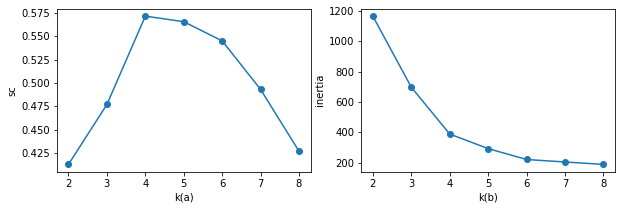

In [23]:
plt.figure(figsize=(10, 3))
ax1 = plt.subplot(121)
plt.plot(range(2, 9), sc, marker='o')
ax1.set_xlabel('k(a)')
ax1.set_ylabel('sc')

ax2 = plt.subplot(122)
plt.plot(range(2, 9), inertia, marker='o')
ax2.set_xlabel('k(b)')
ax2.set_ylabel('inertia')
plt.show()

### 任务3— 使用k=4聚类，绘制聚类后的散点图

In [24]:
kmeans4 = KMeans(n_clusters=4, random_state=151).fit(df_scaler)

In [25]:
kmeans4.labels_

array([2, 1, 1, 1, 2, 1, 2, 1, 2, 1, 1, 2, 1, 2, 1, 2, 1, 2, 2, 1, 2, 1,
       1, 2, 1, 2, 1, 2, 1, 2, 2, 1, 1, 2, 1, 2, 1, 2, 1, 2, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 2, 1, 2, 1, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 2, 1, 1, 2, 1, 2, 1, 2, 2, 1, 2, 1, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 2, 1, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 2, 1, 1, 2, 1, 2, 2, 1, 2, 1, 1, 2, 1, 2, 2, 1, 1, 2, 1,
       2, 1, 2, 1, 2, 2, 1, 2, 1, 1, 2, 1, 2, 2, 1, 3, 0, 3, 0, 0, 3, 3,
       0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 0, 3, 3, 0, 3, 0, 0, 3, 0,
       0, 3, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 0, 3, 3, 0, 3, 0, 3, 0,
       3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 0, 3, 0, 3, 0, 0, 3, 3,
       0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0,

In [27]:
kmeans4.cluster_centers_

array([[ 1.0027816 , -0.73140008,  1.46328141,  1.58598843, -0.99103121,
         0.99700149],
       [-0.69990374,  0.23648629, -0.8542276 , -0.98081025,  1.00904996,
        -1.00300753],
       [-0.02653004,  1.00341299, -0.44645776, -0.25085457, -0.99103121,
         0.99700149],
       [ 0.28020689, -1.47543058,  0.83841882,  0.5896947 ,  0.97515028,
        -1.00300753]])

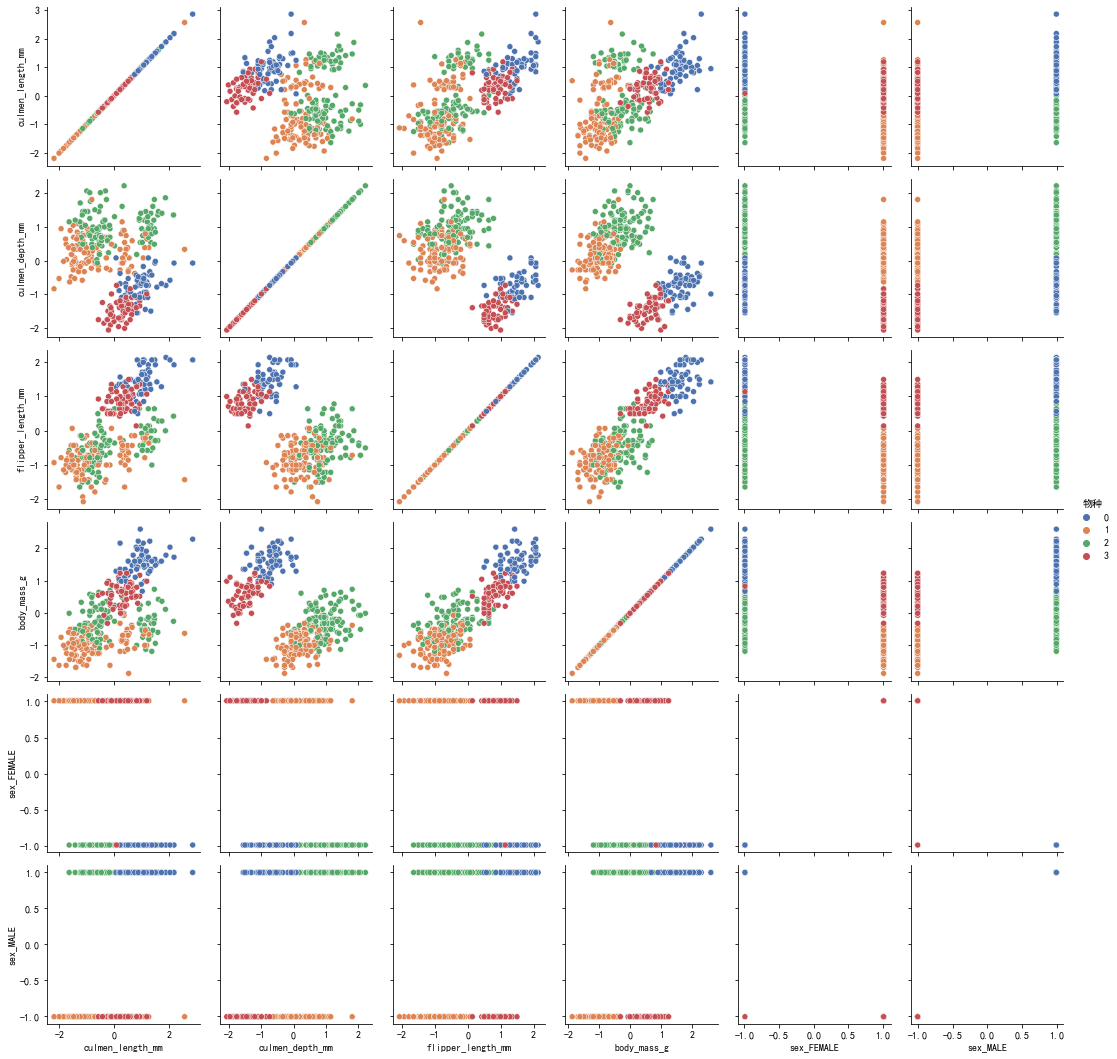

In [28]:
import seaborn as sns
df_scaler['物种'] = kmeans4.labels_
plt.rcParams['font.family'] = 'SimHei'
plt.rcParams['axes.unicode_minus'] = False
g = sns.PairGrid(df_scaler, hue='物种', palette='deep')
g.map(sns.scatterplot)
g.add_legend()
plt.show()